# Task 3, Step 4: Parallel Sampling Versus Sequential Refinement

**Manual step 4.** Fixed 50 MATH questions and one 3,072-token output allowance per question:

| Strategy | Generation and final answer |
|---|---|
| Single longer response | One response capped at 3,072 tokens |
| Parallel sampling | Three independent responses capped at 1,024 tokens; self-consistency selects |
| Sequential refinement | Initial response capped at 1,024, then one critique-and-revision capped at 2,048; return the revised answer |

The first parallel response is the shared initial response. These FP16 runs are a new controlled comparison, not a reproduction of the supplied samples. Generation needs a GPU and resumes if interrupted.

In [1]:
import os, sys, json
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "task3_test_time_compute")):
    root = os.path.dirname(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from task3_test_time_compute.src.notebook_utils import *
setup_notebook()

In [2]:
import torch
from task3_test_time_compute.src.data import FOLDERS, load_and_join_rollouts
from task3_test_time_compute.src.live_generation import run_live_experiment, summarize_live, MODEL_NAME
from task3_test_time_compute.src.normalization import MathEquivalence, scorer_version

live_path = f"{RESULTS_DIR}/live_generations.jsonl"
_, _, splits = split_questions("math")
live_ids = splits["live"]
if torch.cuda.is_available():
    table = pd.read_parquet(os.path.join(DATA_DIR, FOLDERS["math"], "generations.parquet"), columns=["sample_id", "question_text", "gold_answer"]).drop_duplicates("sample_id").set_index("sample_id")
    questions = [{"sample_id": i, "problem": table.loc[i, "question_text"], "gold": table.loc[i, "gold_answer"]} for i in live_ids]
    run_live_experiment(questions, live_path)
elif not os.path.exists(live_path):
    raise RuntimeError("Live generation needs a GPU, and no saved generations exist yet.")

with open(live_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f]
print(f"{len(records)} of {len(live_ids)} questions finished. Scorer: {scorer_version()}")
rows = pd.DataFrame(summarize_live(records, MathEquivalence()))
rows.to_csv(f"{RESULTS_DIR}/live_summary.csv", index=False)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (52 outputs left out)

[Live] 48/50 test:1916


[Live] 49/50 test:3409


[Live] 50/50 test:3617


50 of 50 questions finished. Scorer: math-verify 0.9.0


## 4.1 Accuracy and actual cost
Early termination can leave part of an allowance unused, so actual tokens and runtime are reported alongside accuracy. Refinement is charged the shared initial response, and its input count includes the longer revision prompt.

,accuracy,extraction,truncation,input_tokens,output_tokens,seconds
strategy,,,,,,
Single long,62.0,96.0,4.0,108.38,686.38,34.46
Parallel (3),66.0,90.0,24.0,325.14,1863.42,92.34
Refinement,64.0,100.0,12.0,863.60,1151.04,58.11
Initial only,60.0,88.0,12.0,108.38,609.72,30.30


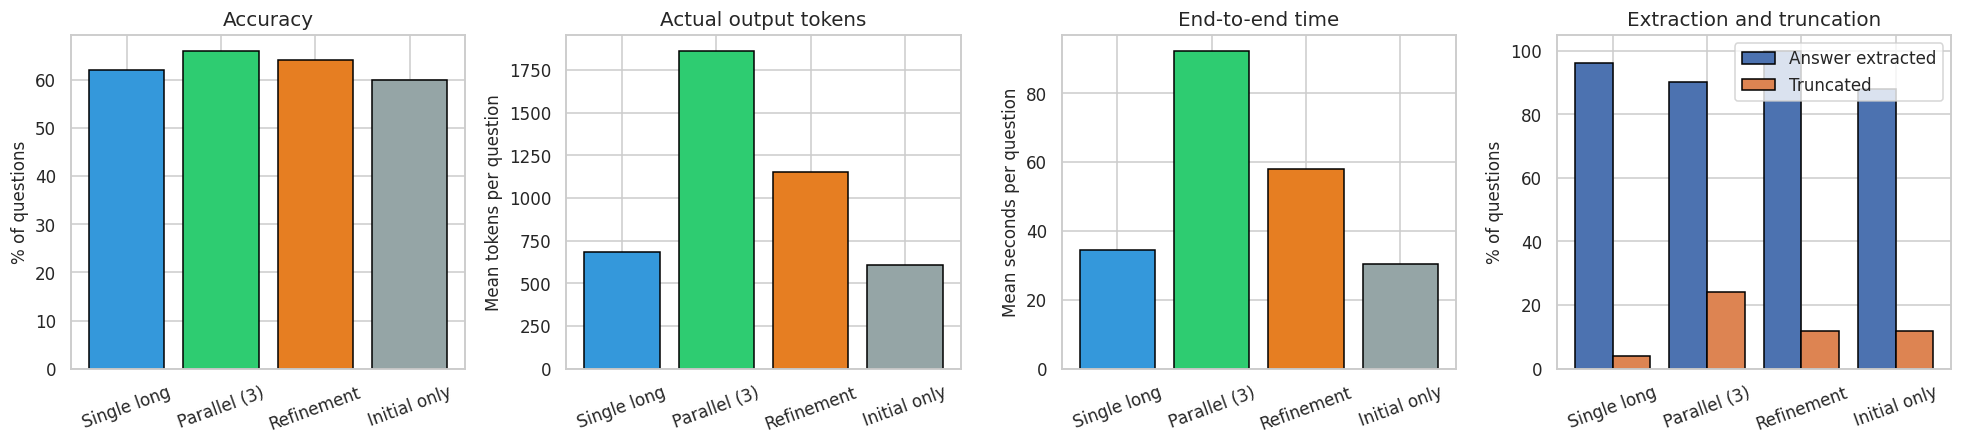

Peak GPU memory (MB): 6314.376953125


In [3]:
order = ["single_long", "parallel", "refinement", "initial_only"]
names = {"single_long": "Single long", "parallel": "Parallel (3)", "refinement": "Refinement", "initial_only": "Initial only"}
summary = rows.groupby("strategy").agg(accuracy=("correct", "mean"), extraction=("extracted", "mean"), truncation=("truncated", "mean"),
                                       input_tokens=("input_tokens", "mean"), output_tokens=("output_tokens", "mean"), seconds=("seconds", "mean")).loc[order]
summary[["accuracy", "extraction", "truncation"]] *= 100
summary.round(2).to_csv(f"{RESULTS_DIR}/live_strategy_table.csv")
display(summary.round(2).rename(index=names))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
colors = ["#3498db", "#2ecc71", "#e67e22", "#95a5a6"]
for ax, column, title, ylabel in zip(axes, ["accuracy", "output_tokens", "seconds"], ["Accuracy", "Actual output tokens", "End-to-end time"], ["% of questions", "Mean tokens per question", "Mean seconds per question"]):
    ax.bar([names[s] for s in order], summary[column], color=colors, edgecolor="black")
    ax.set(title=title, ylabel=ylabel); ax.tick_params(axis="x", rotation=20)
x = np.arange(len(order))
axes[3].bar(x - 0.2, summary["extraction"], 0.4, label="Answer extracted", edgecolor="black")
axes[3].bar(x + 0.2, summary["truncation"], 0.4, label="Truncated", edgecolor="black")
axes[3].set_xticks(x); axes[3].set_xticklabels([names[s] for s in order], rotation=20)
axes[3].set(title="Extraction and truncation", ylabel="% of questions"); axes[3].legend()
save_figure("task3_4_live_strategies")
print("Peak GPU memory (MB):", max(r.get("peak_gpu_mb", 0) for r in records))

## 4.2 What did revision change?
Transitions are relative to the shared initial answer. Gold answers are used only here, for analysis, and never to choose between initial and revised outputs.

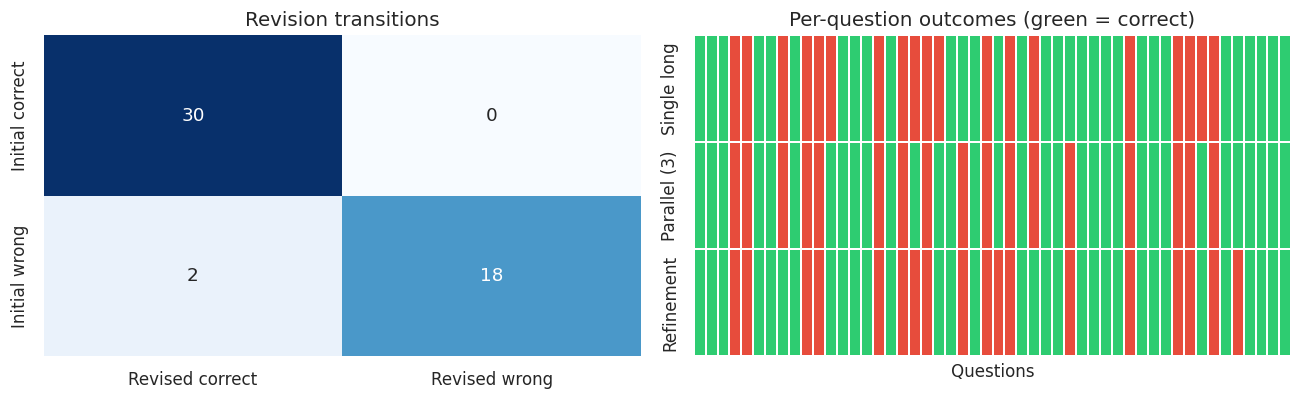

In [4]:
pivot = rows.pivot(index="sample_id", columns="strategy", values="correct").astype(bool)
transitions = pd.crosstab(pivot["initial_only"].map({True: "Initial correct", False: "Initial wrong"}), pivot["refinement"].map({True: "Revised correct", False: "Revised wrong"}))
transitions.to_csv(f"{RESULTS_DIR}/live_revision_transitions.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(transitions, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Revision transitions", xlabel="", ylabel="")
agreement = pivot[["single_long", "parallel", "refinement"]].rename(columns=names)
sns.heatmap(agreement.astype(int).T, cmap=["#e74c3c", "#2ecc71"], cbar=False, ax=axes[1], xticklabels=False, linewidths=0.3)
axes[1].set(title="Per-question outcomes (green = correct)", xlabel="Questions", ylabel="")
save_figure("task3_4_revision_transitions")

## 4.3 Aligned examples
**Selection rule, fixed before viewing:** the first question in live order where the initial answer and the revised answer differ. If there is none, the first question.

In [5]:
from task3_test_time_compute.src.normalization import normalize_math_answer
example = next((r for r in records if normalize_math_answer(r["parallel"][0]["extracted"]) != normalize_math_answer(r["revision"]["extracted"])), records[0])
display(Markdown(f"**Question {example['sample_id']}.** {example['problem'][:800]}\n\n**Gold:** `{example['gold']}`"))
table = pd.DataFrame([{"Output": "Initial", "Answer": example["parallel"][0]["extracted"], "Tokens": example["parallel"][0]["output_tokens"], "Excerpt": example["parallel"][0]["response"][-240:]},
                      {"Output": "Revised", "Answer": example["revision"]["extracted"], "Tokens": example["revision"]["output_tokens"], "Excerpt": example["revision"]["response"][-240:]},
                      {"Output": "Single long", "Answer": example["single"]["extracted"], "Tokens": example["single"]["output_tokens"], "Excerpt": example["single"]["response"][-240:]}])
with pd.option_context("display.max_colwidth", None):
    display(table)

**Question test:2892.** There is a unique polynomial $P(x)$ of degree $8$ with rational coefficients and leading coefficient $1,$ which has the number \[\sqrt{2} + \sqrt{3} + \sqrt{5}\]as a root. Compute $P(1).$

**Gold:** `-71`

,Output,Answer,Tokens,Excerpt
0,Initial,None,1024,he radicals:**\n \[\n \left( \frac{\left( \frac{\alpha^2 - 10}{2} \right)^2 - 31}{2} \right)^2 - 200 = 4\sqrt{5400} + 4\sqrt{27000}\n \]\n Divide by 4:\n \[\n \frac{\left( \frac{\left( \frac{\alpha^2 - 10}{2} \right)^2 - 31}{2} \right
1,Revised,0,1745,"cdot 1^4 - 1792 \cdot 1^3 + 1344 \cdot 1^2 - 512 \cdot 1 + 64\n\]\n\[\nP(1) = 1 - 16 + 112 - 448 + 1120 - 1792 + 1344 - 512 + 64\n\]\n\[\nP(1) = 1 - 16 + 112 - 448 + 1120 - 1792 + 1344 - 512 + 64 = 0\n\]\n\nThus, the final answer is:\n\[\n\boxed{0}\n\]"
2,Single long,-2,1023,"s. The polynomial is:\n\[\nP(x) = (x^8 - 20x^6 + 32x^4 - 16x^2 + 1).\n\]\nWe need to compute \(P(1)\):\n\[\nP(1) = 1^8 - 20 \cdot 1^6 + 32 \cdot 1^4 - 16 \cdot 1^2 + 1 = 1 - 20 + 32 - 16 + 1 = -2.\n\]\nThus, the value of \(P(1)\) is \(\boxed{-2}\)."
